# Water Tank Monitoring & Remaining Water Prediction
## Linear Regression — Google Colab notebook




## 1. Import libraries


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
print('Libraries loaded successfully')


Libraries loaded successfully


## 2. Create a demo dataset

Each row represents a forecast scenario. `Usage_Rate_L_per_hour` is the **average usage rate expected during the forecast period**. The target is calculated from the water-balance equation plus small simulated measurement noise. This lets us practise the workflow before real sensor readings are available.


In [ ]:
TANK_CAPACITY_L = 1000
N_ROWS = 1500

current_water = np.random.uniform(50, TANK_CAPACITY_L, N_ROWS)
usage_rate = np.random.uniform(0, 80, N_ROWS)       # litres/hour
hours_ahead = np.random.uniform(0.25, 12, N_ROWS)  # hours into the future

# Simulated measurement/model variation (litres)
noise = np.random.normal(loc=0, scale=5, size=N_ROWS)

# Simulated target: water remaining after the forecast period
remaining = current_water - (usage_rate * hours_ahead) + noise
remaining = np.clip(remaining, 0, TANK_CAPACITY_L)

df = pd.DataFrame({
    'Time_Ahead_Hours': hours_ahead,
    'Water_Level_L': current_water,
    'Usage_Rate_L_per_hour': usage_rate,
    'Remaining_Water_L': remaining
})

df.to_csv('water_tank_simulated_raw.csv', index=False)
df.head()


,Time_Ahead_Hours,Water_Level_L,Usage_Rate_L_per_hour,Remaining_Water_L
0,8.154260,405.813113,41.526543,68.928428
1,9.611006,953.178591,38.334550,597.302766
2,3.192998,745.394245,2.051365,729.643851
3,7.592271,618.725560,27.299826,411.296487
4,6.968015,198.217708,30.415650,0.000000


## 3. Inspect and clean the data
We check the data types, missing values, duplicate rows, and physically impossible values. Do not silently delete unusual values in real data: first check whether they are sensor errors or genuine events.


In [ ]:
print('Shape:', df.shape)
display(df.head())
print('\nData types:')
print(df.dtypes)
print('\nMissing values:')
print(df.isna().sum())
print('\nDuplicate rows:', df.duplicated().sum())

df_clean = df.drop_duplicates().copy()
numeric_cols = ['Time_Ahead_Hours', 'Water_Level_L', 'Usage_Rate_L_per_hour', 'Remaining_Water_L']
for col in numeric_cols:
    df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

df_clean = df_clean.dropna(subset=numeric_cols)
df_clean = df_clean[
    (df_clean['Time_Ahead_Hours'] >= 0) &
    (df_clean['Water_Level_L'] >= 0) &
    (df_clean['Water_Level_L'] <= TANK_CAPACITY_L) &
    (df_clean['Usage_Rate_L_per_hour'] >= 0) &
    (df_clean['Remaining_Water_L'] >= 0) &
    (df_clean['Remaining_Water_L'] <= TANK_CAPACITY_L)
].copy()

print('Rows after cleaning:', len(df_clean))
display(df_clean.describe().round(2))
df_clean.to_csv('water_tank_cleaned.csv', index=False)


Shape: (1500, 4)


,Time_Ahead_Hours,Water_Level_L,Usage_Rate_L_per_hour,Remaining_Water_L
0,8.154260,405.813113,41.526543,68.928428
1,9.611006,953.178591,38.334550,597.302766
2,3.192998,745.394245,2.051365,729.643851
3,7.592271,618.725560,27.299826,411.296487
4,6.968015,198.217708,30.415650,0.000000



Data types:
Time_Ahead_Hours         float64
Water_Level_L            float64
Usage_Rate_L_per_hour    float64
Remaining_Water_L        float64
dtype: object

Missing values:
Time_Ahead_Hours         0
Water_Level_L            0
Usage_Rate_L_per_hour    0
Remaining_Water_L        0
dtype: int64

Duplicate rows: 0
Rows after cleaning: 1500


,Time_Ahead_Hours,Water_Level_L,Usage_Rate_L_per_hour,Remaining_Water_L
count,1500.00,1500.00,1500.00,1500.00
mean,6.00,524.39,40.03,327.19
std,3.35,279.31,23.15,282.73
min,0.25,54.40,0.00,0.00
25%,3.09,275.67,20.59,47.72
50%,5.98,531.23,40.40,286.77
75%,8.82,765.99,60.36,562.33
max,11.99,999.73,79.87,993.55


## 4. Explore the dataset


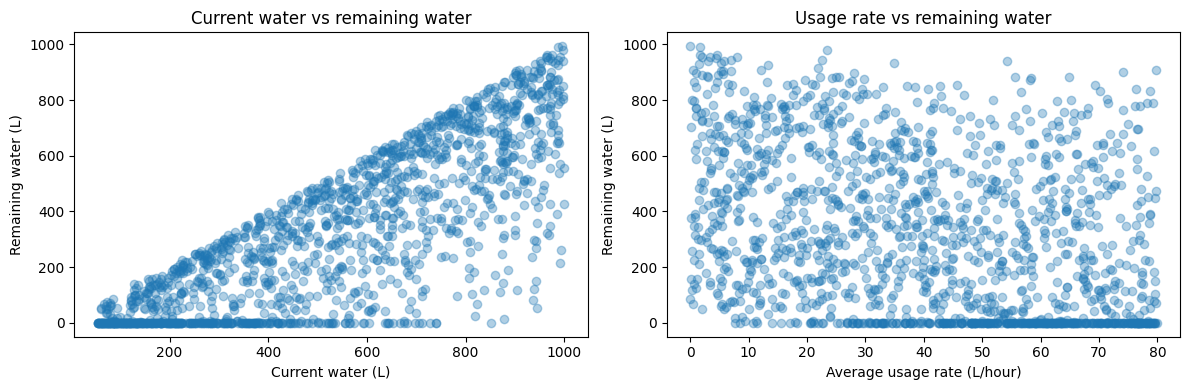

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(df_clean['Water_Level_L'], df_clean['Remaining_Water_L'], alpha=0.35)
axes[0].set_xlabel('Current water (L)')
axes[0].set_ylabel('Remaining water (L)')
axes[0].set_title('Current water vs remaining water')

axes[1].scatter(df_clean['Usage_Rate_L_per_hour'], df_clean['Remaining_Water_L'], alpha=0.35)
axes[1].set_xlabel('Average usage rate (L/hour)')
axes[1].set_ylabel('Remaining water (L)')
axes[1].set_title('Usage rate vs remaining water')
plt.tight_layout()
plt.show()


## 5. Select inputs and target, then split the data

Inputs (`X`): forecast time, current water level, and average usage rate. Target (`y`): remaining water. The test set is held out to estimate performance on unseen examples.


In [ ]:
feature_cols = ['Time_Ahead_Hours', 'Water_Level_L', 'Usage_Rate_L_per_hour']
target_col = 'Remaining_Water_L'

X = df_clean[feature_cols]
y = df_clean[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_SEED
)

print('Training rows:', len(X_train))
print('Testing rows:', len(X_test))


Training rows: 1200
Testing rows: 300


## 6. Train the Linear Regression model

The model learns coefficients from training examples. In general, its equation is:

`Predicted remaining water = intercept + b1 × time + b2 × current water + b3 × usage rate`

The coefficients are learned from data; they are not manually chosen.


In [ ]:
model = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('regressor', LinearRegression())
])

model.fit(X_train, y_train)
print('Model trained successfully')

reg = model.named_steps['regressor']
print('Intercept:', round(reg.intercept_, 4))
print('Coefficients:')
for name, coef in zip(feature_cols, reg.coef_):
    print(f'  {name}: {coef:.4f}')


Model trained successfully
Intercept: 236.2409
Coefficients:
  Time_Ahead_Hours: -28.6069
  Water_Level_L: 0.8247
  Usage_Rate_L_per_hour: -4.3011


## 7. Evaluate the model on the test set

MAE and RMSE are in litres. R² indicates how much variation is explained by the model. These scores are for simulated data and should not be reported as real-world performance.


MAE:  68.04 litres
RMSE: 87.41 litres
R²:   0.908


,Actual_L,Predicted_L
0,0.00,-90.28
1,179.99,258.98
2,0.00,-127.65
3,464.43,471.71
4,438.50,405.08
5,216.97,274.58
6,426.53,487.49
7,307.93,219.76
8,659.54,552.74
9,0.00,-143.15


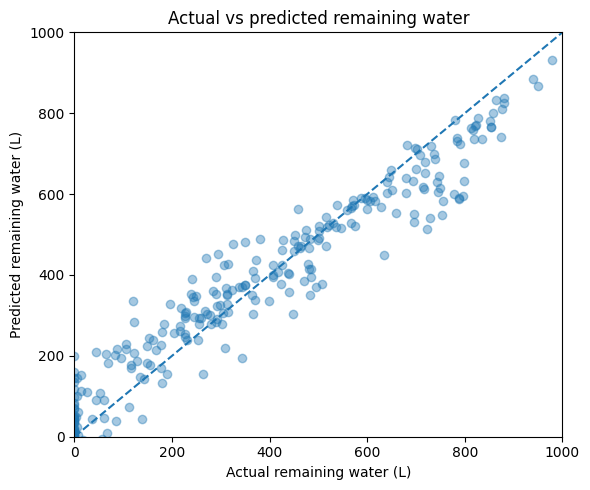

In [ ]:
y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f'MAE:  {mae:.2f} litres')
print(f'RMSE: {rmse:.2f} litres')
print(f'R²:   {r2:.3f}')

results = pd.DataFrame({'Actual_L': y_test.values, 'Predicted_L': y_pred})
display(results.head(10).round(2))

plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred, alpha=0.4)
plt.xlabel('Actual remaining water (L)')
plt.ylabel('Predicted remaining water (L)')
plt.title('Actual vs predicted remaining water')
plt.plot([0, TANK_CAPACITY_L], [0, TANK_CAPACITY_L], linestyle='--')
plt.xlim(0, TANK_CAPACITY_L)
plt.ylim(0, TANK_CAPACITY_L)
plt.tight_layout()
plt.show()


## 8. Make a prediction for a new situation

Edit the three values below. `Usage_Rate_L_per_hour` should represent the expected **average rate across the prediction period**. The final clipping only enforces physical display limits; it does not improve the model itself.


In [ ]:
def predict_remaining_water(current_water_l, usage_rate_l_per_hour, hours_ahead, tank_capacity_l=TANK_CAPACITY_L):
    if tank_capacity_l <= 0:
        raise ValueError('Tank capacity must be greater than zero.')
    if not (0 <= current_water_l <= tank_capacity_l):
        raise ValueError('Current water must be between 0 and tank capacity.')
    if usage_rate_l_per_hour < 0 or hours_ahead < 0:
        raise ValueError('Usage rate and forecast time cannot be negative.')

    new_input = pd.DataFrame([{
        'Time_Ahead_Hours': hours_ahead,
        'Water_Level_L': current_water_l,
        'Usage_Rate_L_per_hour': usage_rate_l_per_hour
    }])
    raw_prediction = float(model.predict(new_input)[0])
    bounded_prediction = float(np.clip(raw_prediction, 0, min(current_water_l, tank_capacity_l)))
    return raw_prediction, bounded_prediction

# Example: 600 L now, average use 20 L/hour, forecast 5 hours
raw, predicted = predict_remaining_water(600, 20, 5)
print(f'Raw model prediction: {raw:.2f} L')
print(f'Displayed prediction (bounded): {predicted:.2f} L')


Raw model prediction: 502.00 L
Displayed prediction (bounded): 502.00 L


## 9. Show how changing usage rate changes the prediction

The model does not automatically detect a new usage rate. You must update the rate input and request a new prediction. These scenarios use the same current water and forecast horizon.


In [ ]:
current_water_demo = 600
hours_demo = 5
rates_to_test = [10, 20, 40, 60]

scenario_rows = []
for rate in rates_to_test:
    raw, bounded = predict_remaining_water(current_water_demo, rate, hours_demo)
    scenario_rows.append({
        'Current_Water_L': current_water_demo,
        'Average_Usage_Rate_L_per_hour': rate,
        'Hours_Ahead': hours_demo,
        'Raw_Model_Prediction_L': round(raw, 2),
        'Displayed_Prediction_L': round(bounded, 2)
    })

display(pd.DataFrame(scenario_rows))

# Compare with the basic water-balance calculation for a constant rate
print('\nBasic water-balance calculation (constant usage):')
for rate in rates_to_test:
    expected = np.clip(current_water_demo - rate * hours_demo, 0, TANK_CAPACITY_L)
    print(f'{rate:>2} L/hour -> {expected:.0f} L remaining')


,Current_Water_L,Average_Usage_Rate_L_per_hour,Hours_Ahead,Raw_Model_Prediction_L,Displayed_Prediction_L
0,600,10,5,545.01,545.01
1,600,20,5,502.00,502.00
2,600,40,5,415.98,415.98
3,600,60,5,329.96,329.96



Basic water-balance calculation (constant usage):
10 L/hour -> 550 L remaining
20 L/hour -> 500 L remaining
40 L/hour -> 400 L remaining
60 L/hour -> 300 L remaining


## 10. Save the model and cleaned dataset

The files will appear in the Colab file panel. Download them before ending the session if you need them later.


In [ ]:
import joblib
joblib.dump(model, 'water_tank_linear_regression.joblib')
df_clean.to_csv('water_tank_cleaned.csv', index=False)
print('Saved: water_tank_linear_regression.joblib')
print('Saved: water_tank_cleaned.csv')

# Optional: download the saved files from Google Colab
from google.colab import files
files.download('water_tank_linear_regression.joblib')
files.download('water_tank_cleaned.csv')


Saved: water_tank_linear_regression.joblib
Saved: water_tank_cleaned.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:

import joblib

# Save the trained model
joblib.dump(model, "/content/water_tank_model.pkl")

# Confirm that the file was created
import os
print(os.path.exists("/content/water_tank_model.pkl"))


True


In [12]:

import joblib
import sklearn

print("Scikit-learn version:", sklearn.__version__)

# Get the trained model
trained_model = model

# If model is a Pipeline, extract its final estimator
if hasattr(trained_model, "steps"):
    trained_model = trained_model.steps[-1][1]

# Save the regression estimator
joblib.dump(trained_model, "water_tank_model.pkl")

print("Model saved successfully!")
print("Saved model type:", type(trained_model).__name__)


Scikit-learn version: 1.6.1
Model saved successfully!
Saved model type: LinearRegression
